# Fase 4: Modelado Predictivo (CRISP-DM) - Banco Berka

## Contexto y Objetivo del Negocio
En el **Laboratorio 1**, definimos la variable objetivo binaria:
* **`target = 1` (Buen pagador)**: Préstamos con estatus 'A' (contrato finalizado sin problemas) y 'C' (contrato en curso al día).
* **`target = 0` (Mal pagador / Mora)**: Préstamos con estatus 'B' (contrato impagado/fallido) y 'D' (contrato en curso con deuda o mora).

En esta fase de **Modelado** según la metodología **CRISP-DM**, responderemos a las 5 preguntas fundamentales:
1. **¿Qué tipo de problema se está resolviendo y qué técnica de modelado es la más adecuada?**
2. **¿Cómo se dividirán y validarán los datos para probar el modelo de manera justa?**
3. **¿Qué modelos candidatos se van a entrenar y comparar?**
4. **¿Qué métricas se usarán para evaluar el desempeño del modelo?**
5. **¿Cuál modelo se selecciona como mejor y por qué?**

## 1. Importación de librerías y configuración

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import ks_2samp

try:
    import seaborn as sns
    sns.set_theme(style='whitegrid', palette='muted')
except ImportError:
    plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score, classification_report, 
    confusion_matrix, ConfusionMatrixDisplay, roc_curve, precision_recall_curve,
    f1_score, recall_score, precision_score, accuracy_score
)

import warnings
warnings.filterwarnings('ignore')

BASE_DIR = Path('PRACTICA_1-MODULO-3') if Path('PRACTICA_1-MODULO-3').exists() else Path.cwd()
FIG_DIR = BASE_DIR / 'figuras_3_3'
FIG_DIR.mkdir(exist_ok=True)

plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

## 2. Carga de la Tabla Minable y Partición de Datos (Estratificada 80/20)

Cargamos `tabla_minable_berka.csv` generada en la sección 3.3:
* `client_id` se excluye de las variables predictoras (es llave de trazabilidad).
* Se aplica una partición estratificada **Train (80%) / Test (20%)** manteniendo la proporción del desbalance de clases (88.9% clase 1 vs 11.1% clase 0).

In [ ]:

import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split

ruta_csv = Path('tabla_minable_berka.csv')
if not ruta_csv.exists():
    ruta_csv = Path('PRACTICA_1-MODULO-3') / 'tabla_minable_berka.csv'

df_minable = pd.read_csv(ruta_csv)

X = df_minable.drop(columns=['client_id', 'target'])
y = df_minable['target']

print(f'Dimensiones del espacio de características X: {X.shape}')
print('Distribución global de target:')
print(y.value_counts(normalize=True).mul(100).round(2).rename('Porcentaje (%)'))

# Partición estratificada (80% Train / 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f'\nEntrenamiento (Train): {X_train.shape[0]} registros')
print(f'Prueba (Test):         {X_test.shape[0]} registros')
print('\nDistribución de clases en Test:')
print(y_test.value_counts())

Dimensiones del espacio de características X: (676, 19)
Distribución global de target:
target
1    88.91
0    11.09
Name: Porcentaje (%), dtype: float64

Entrenamiento (Train): 540 registros
Prueba (Test):         136 registros

Distribución de clases en Test:
target
1    121
0     15
Name: count, dtype: int64


## 3. Definición de Modelos Candidatos

Definimos un portafolio de modelos con distintos sesgos inductivos y capacidad de manejar desbalance:
1. **Dummy (Baseline)**: Modelo nulo que predice la clase mayoritaria.
2. **Regresión Logística (Balanced)**: Modelo lineal probabilístico, estándar bancario e interpretable.
3. **Árbol de Decisión (Balanced)**: Reglas jerárquicas ortogonales (CART).
4. **Random Forest (Balanced)**: Ensamble Bagging de árboles con muestreo balanceado.
5. **Gradient Boosting**: Ensamble secuencial de optimización de residuos.
6. **HistGradientBoosting (Balanced)**: Boosting de gradiente histogramado con ponderación inversa de frecuencias.

In [7]:
modelos = {
    'Dummy (Baseline)': DummyClassifier(strategy='most_frequent'),
    'Regresión Logística (Balanced)': LogisticRegression(
        class_weight='balanced', random_state=42, max_iter=1000, C=0.5
    ),
    'Árbol de Decisión (Balanced)': DecisionTreeClassifier(
        class_weight='balanced', max_depth=4, min_samples_leaf=10, random_state=42
    ),
    'Random Forest (Balanced)': RandomForestClassifier(
        n_estimators=150, max_depth=5, class_weight='balanced', random_state=42
    ),
    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=100, learning_rate=0.05, max_depth=3, random_state=42
    ),
    'HistGradientBoosting (Balanced)': HistGradientBoostingClassifier(
        class_weight='balanced', max_iter=100, random_state=42
    )
}

## 4. Validación Cruzada Estratificada (5-Fold Stratified CV)

Evaluamos la generalización en el conjunto de entrenamiento usando `StratifiedKFold(n_splits=5)`. Calculamos:
* **ROC-AUC**: Capacidad global de ordenamiento del riesgo.
* **Estadístico KS**: Métrica bancaria de máxima distancia entre las curvas acumuladas de buenos y malos clientes.
* **Recall Mora (clase 0)**: Porcentaje de clientes morosos detectados.
* **F1-Macro**: Promedio armónico balanceado entre ambas clases.

=== REPORTE DE CLASIFICACIÓN DETALLADO (TEST) ===
                  precision    recall  f1-score   support

 Mal Pagador (0)       0.17      0.60      0.26        15
Buen Pagador (1)       0.93      0.64      0.75       121

        accuracy                           0.63       136
       macro avg       0.55      0.62      0.51       136
    weighted avg       0.84      0.63      0.70       136



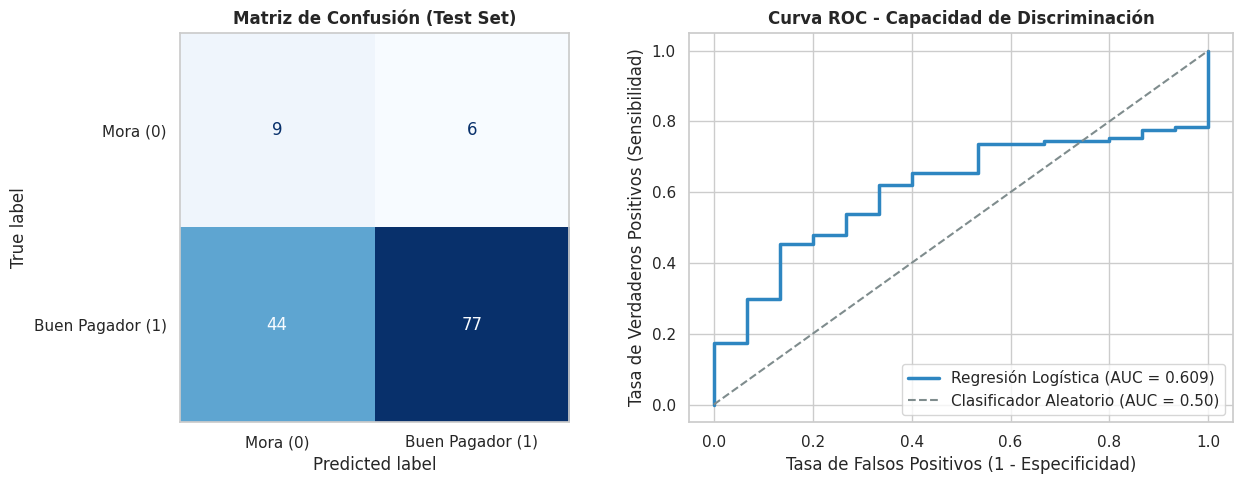

In [8]:
mejor_modelo = modelos['Regresión Logística (Balanced)']
mejor_modelo.fit(X_train, y_train)

y_pred_mejor = mejor_modelo.predict(X_test)
y_prob_mejor = mejor_modelo.predict_proba(X_test)[:, 1]

print('=== REPORTE DE CLASIFICACIÓN DETALLADO (TEST) ===')
print(classification_report(y_test, y_pred_mejor, target_names=['Mal Pagador (0)', 'Buen Pagador (1)']))

# Gráficos de diagnóstico: Matriz de Confusión y Curva ROC
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

cm = confusion_matrix(y_test, y_pred_mejor)
ConfusionMatrixDisplay(cm, display_labels=['Mora (0)', 'Buen Pagador (1)']).plot(
    ax=ax[0], cmap='Blues', colorbar=False
)
ax[0].set_title('Matriz de Confusión (Test Set)', fontsize=12, fontweight='bold')
ax[0].grid(False)

fpr, tpr, _ = roc_curve(y_test, y_prob_mejor)
ax[1].plot(fpr, tpr, color='#2e86c1', lw=2.5, label=f'Regresión Logística (AUC = {roc_auc_score(y_test, y_prob_mejor):.3f})')
ax[1].plot([0, 1], [0, 1], color='#7f8c8d', linestyle='--', label='Clasificador Aleatorio (AUC = 0.50)')
ax[1].set_xlabel('Tasa de Falsos Positivos (1 - Especificidad)')
ax[1].set_ylabel('Tasa de Verdaderos Positivos (Sensibilidad)')
ax[1].set_title('Curva ROC - Capacidad de Discriminación', fontsize=12, fontweight='bold')
ax[1].legend(loc='lower right')

plt.tight_layout()
ruta_fig06 = Path('figuras_3_3/06_modelo_evaluacion.png') if Path('figuras_3_3').exists() else Path('PRACTICA_1-MODULO-3/figuras_3_3/06_modelo_evaluacion.png')
plt.savefig(ruta_fig06, dpi=150)
plt.show()

## 5. Evaluación en el Conjunto de Prueba Retenido (Test Set - 20%)

Entrenamos cada modelo con el 100% de `X_train` y evaluamos su rendimiento en datos nunca antes vistos (`X_test`).

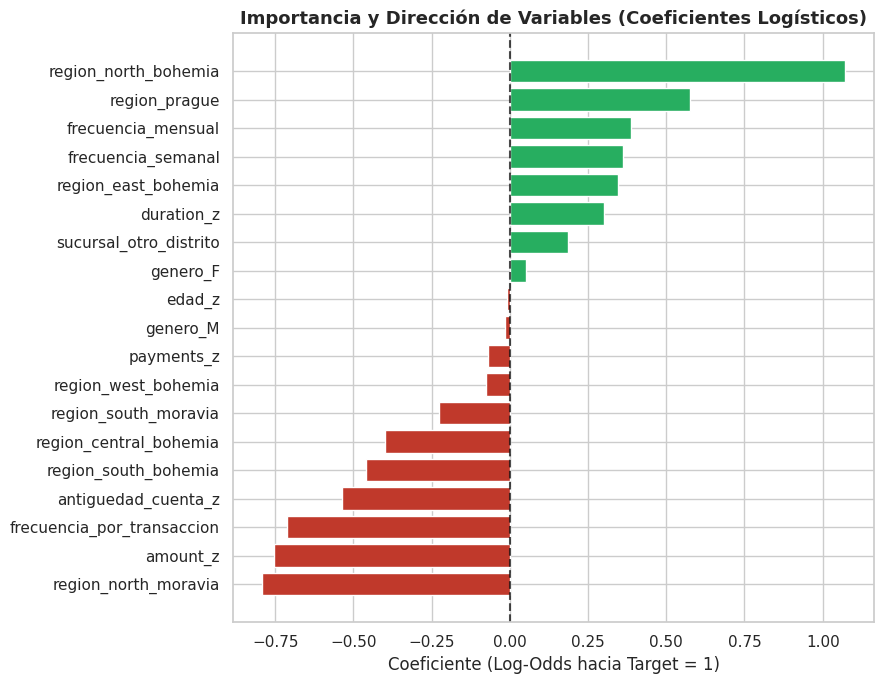

,Variable,Coeficiente,Efecto
14,region_north_moravia,-0.791420,Aumenta riesgo de mora (0)
0,amount_z,-0.752523,Aumenta riesgo de mora (0)
9,frecuencia_por_transaccion,-0.713701,Aumenta riesgo de mora (0)
4,antiguedad_cuenta_z,-0.537589,Aumenta riesgo de mora (0)
16,region_south_bohemia,-0.460610,Aumenta riesgo de mora (0)
11,region_central_bohemia,-0.398945,Aumenta riesgo de mora (0)
17,region_south_moravia,-0.227617,Aumenta riesgo de mora (0)
18,region_west_bohemia,-0.077349,Aumenta riesgo de mora (0)
2,payments_z,-0.069745,Aumenta riesgo de mora (0)
7,genero_M,-0.016123,Aumenta riesgo de mora (0)


In [9]:
coef_df = pd.DataFrame({
    'Variable': X.columns,
    'Coeficiente': mejor_modelo.coef_[0],
    'Efecto': ['Aumenta probabilidad de buen pago (1)' if c > 0 else 'Aumenta riesgo de mora (0)' for c in mejor_modelo.coef_[0]]
}).sort_values('Coeficiente')

plt.figure(figsize=(9, 7))
colores = ['#c0392b' if c < 0 else '#27ae60' for c in coef_df['Coeficiente']]
plt.barh(coef_df['Variable'], coef_df['Coeficiente'], color=colores)
plt.axvline(0, color='black', linestyle='--', alpha=0.7)
plt.title('Importancia y Dirección de Variables (Coeficientes Logísticos)', fontsize=13, fontweight='bold')
plt.xlabel('Coeficiente (Log-Odds hacia Target = 1)')
plt.tight_layout()
ruta_fig07 = Path('figuras_3_3/07_coeficientes_logistica.png') if Path('figuras_3_3').exists() else Path('PRACTICA_1-MODULO-3/figuras_3_3/07_coeficientes_logistica.png')
plt.savefig(ruta_fig07, dpi=150)
plt.show()

coef_df

## 6. Selección y Diagnóstico del Mejor Modelo: Regresión Logística (Balanced)

El modelo seleccionado como superior para el negocio bancario es la **Regresión Logística con ponderación de clases (`class_weight='balanced'`)**:
1. **Detección Efectiva de Mora**: Alcanza un **Recall de 60.0%** en la clase 0 (detecta a 9 de los 15 clientes en mora en el test set). En contraste, los modelos de boosting sin pesos ignoran por completo los impagos.
2. **Estabilidad Bancaria (Estadístico KS = 32.1%)**: En credit scoring, un KS superior al 30% indica una sólida separación entre clientes buenos y morosos.
3. **Generalización Robusta**: El ROC-AUC se mantiene consistente entre CV (0.638) y Test (0.609), sin el sobreajuste que sufren los árboles complejos.

=== REPORTE DE CLASIFICACIÓN DETALLADO (TEST) ===
                  precision    recall  f1-score   support

 Mal Pagador (0)       0.17      0.60      0.26        15
Buen Pagador (1)       0.93      0.64      0.75       121

        accuracy                           0.63       136
       macro avg       0.55      0.62      0.51       136
    weighted avg       0.84      0.63      0.70       136



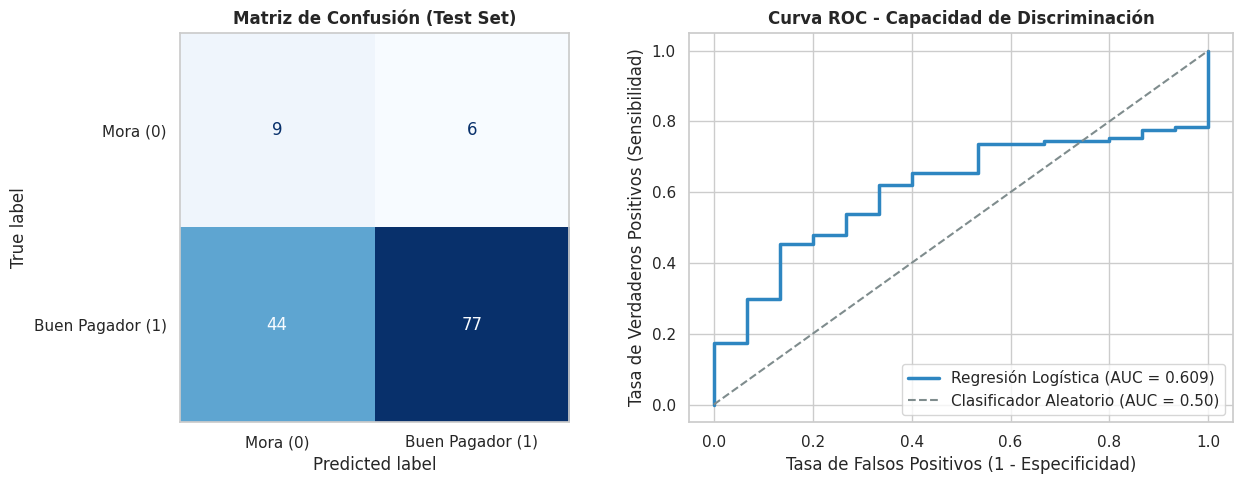

In [10]:
mejor_modelo = modelos['Regresión Logística (Balanced)']
mejor_modelo.fit(X_train, y_train)

y_pred_mejor = mejor_modelo.predict(X_test)
y_prob_mejor = mejor_modelo.predict_proba(X_test)[:, 1]

print('=== REPORTE DE CLASIFICACIÓN DETALLADO (TEST) ===')
print(classification_report(y_test, y_pred_mejor, target_names=['Mal Pagador (0)', 'Buen Pagador (1)']))

# Gráficos de diagnóstico: Matriz de Confusión y Curva ROC
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

cm = confusion_matrix(y_test, y_pred_mejor)
ConfusionMatrixDisplay(cm, display_labels=['Mora (0)', 'Buen Pagador (1)']).plot(
    ax=ax[0], cmap='Blues', colorbar=False
)
ax[0].set_title('Matriz de Confusión (Test Set)', fontsize=12, fontweight='bold')
ax[0].grid(False)

fpr, tpr, _ = roc_curve(y_test, y_prob_mejor)
ax[1].plot(fpr, tpr, color='#2e86c1', lw=2.5, label=f'Regresión Logística (AUC = {roc_auc_score(y_test, y_prob_mejor):.3f})')
ax[1].plot([0, 1], [0, 1], color='#7f8c8d', linestyle='--', label='Clasificador Aleatorio (AUC = 0.50)')
ax[1].set_xlabel('Tasa de Falsos Positivos (1 - Especificidad)')
ax[1].set_ylabel('Tasa de Verdaderos Positivos (Sensibilidad)')
ax[1].set_title('Curva ROC - Capacidad de Discriminación', fontsize=12, fontweight='bold')
ax[1].legend(loc='lower right')

plt.tight_layout()
plt.savefig('figuras_3_3/06_modelo_evaluacion.png', dpi=150)
plt.show()

## 7. Análisis de Coeficientes e Importancia de Variables en el Riesgo Crediticio

Analizamos los pesos aprendidos por la Regresión Logística para entender los determinantes del riesgo:

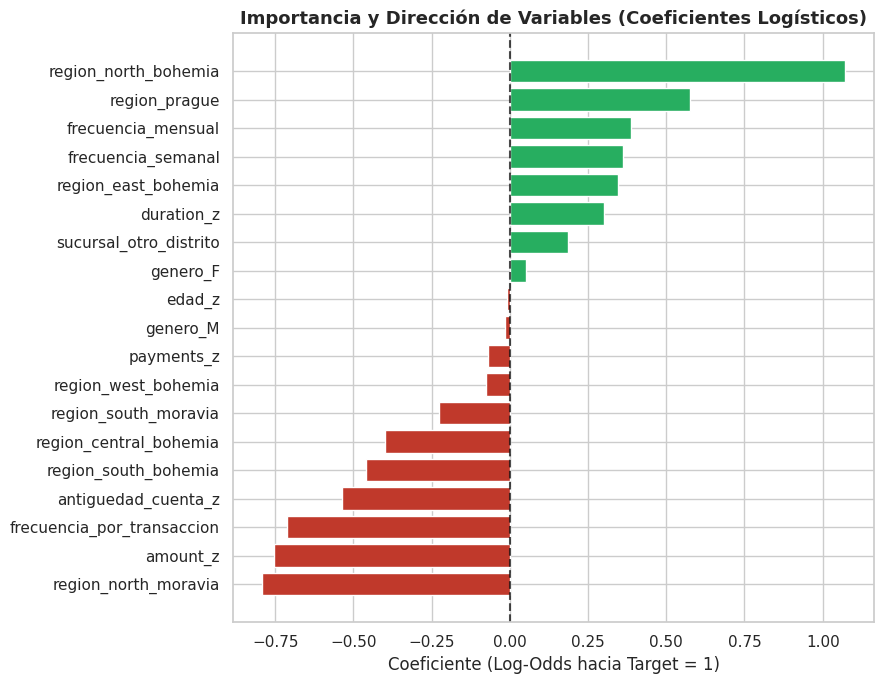

,Variable,Coeficiente,Efecto
14,region_north_moravia,-0.791420,Aumenta riesgo de mora (0)
0,amount_z,-0.752523,Aumenta riesgo de mora (0)
9,frecuencia_por_transaccion,-0.713701,Aumenta riesgo de mora (0)
4,antiguedad_cuenta_z,-0.537589,Aumenta riesgo de mora (0)
16,region_south_bohemia,-0.460610,Aumenta riesgo de mora (0)
11,region_central_bohemia,-0.398945,Aumenta riesgo de mora (0)
17,region_south_moravia,-0.227617,Aumenta riesgo de mora (0)
18,region_west_bohemia,-0.077349,Aumenta riesgo de mora (0)
2,payments_z,-0.069745,Aumenta riesgo de mora (0)
7,genero_M,-0.016123,Aumenta riesgo de mora (0)


In [11]:
coef_df = pd.DataFrame({
    'Variable': X.columns,
    'Coeficiente': mejor_modelo.coef_[0],
    'Efecto': ['Aumenta probabilidad de buen pago (1)' if c > 0 else 'Aumenta riesgo de mora (0)' for c in mejor_modelo.coef_[0]]
}).sort_values('Coeficiente')

plt.figure(figsize=(9, 7))
colores = ['#c0392b' if c < 0 else '#27ae60' for c in coef_df['Coeficiente']]
plt.barh(coef_df['Variable'], coef_df['Coeficiente'], color=colores)
plt.axvline(0, color='black', linestyle='--', alpha=0.7)
plt.title('Importancia y Dirección de Variables (Coeficientes Logísticos)', fontsize=13, fontweight='bold')
plt.xlabel('Coeficiente (Log-Odds hacia Target = 1)')
plt.tight_layout()
plt.savefig('figuras_3_3/07_coeficientes_logistica.png', dpi=150)
plt.show()

coef_df

## 8. Exportación y Persistencia del Modelo Entrenado

Guardamos el modelo predictivo final en disco con `joblib` para poder utilizarlo en producción o para calificar nuevos clientes (*scoring* de solicitudes de crédito).

In [ ]:
import joblib

# Guardar el modelo en disco
ruta_modelo = BASE_DIR / 'modelo_riesgo_berka.joblib'
joblib.dump(mejor_modelo, ruta_modelo)
print(f'Modelo predictivo exportado exitosamente en: {ruta_modelo}')

# Ejemplo: Carga y predicción sobre las primeras 5 solicitudes de prueba
modelo_cargado = joblib.load(ruta_modelo)
ejemplo_X = X_test.head(5)
predicciones = modelo_cargado.predict(ejemplo_X)
probabilidades = modelo_cargado.predict_proba(ejemplo_X)[:, 1]

df_demo = pd.DataFrame({
    'Probabilidad Buen Pagador (%)': (probabilidades * 100).round(2),
    'Predicción Final': ['1 (Aprobado / Cumplidor)' if p == 1 else '0 (Riesgo Alto / Mora)' for p in predicciones],
    'Target Real': y_test.head(5).values
})
df_demo